# Benchmark: consultas con y sin índices

**Responsable:** Thomas (lo ejecuta Juan Arias con la base completa)

**Objetivo:** comparar las dos estrategias de almacenamiento de k-mers en tiempo de consulta, con y sin
índices, usando `explain("executionStats")`. De esto depende la conclusión de la decisión 4 de `MODELO.md`.
La carga y el espacio están en `06_benchmark_carga_espacio.ipynb`.

| Estrategia | Colecciones |
| --- | --- |
| Principal (`coleccion`) | `panteon.kmers` (un documento por TE y por k) y `panteon.tes` |
| Alternativa (`embebido`) | `panteon_bench.tes_embebidos` (k-mers en `kmers.k1`…`kmers.k6`) |

Modelo de referencia: `../MODELO.md`

## Instrucciones para ejecutar

1. Revisar los parámetros de la celda siguiente: `URI`, `DB_PRINCIPAL = "panteon"` y `DB_BENCH = "panteon_bench"`
   (las bases restauradas del dump, ver `resultados/dump_info.md`). El resto se deja como está.
2. Cerrar otras aplicaciones (incluido Docker si no es donde corre MongoDB), conectar el cargador y usar
   `caffeinate`, igual que en el benchmark de carga.
3. *Kernel → Restart & Run All*. Tiempo estimado con la base completa: **entre 15 y 30 minutos**; las
   combinaciones más lentas son Q2 y Q4 sobre `tes_embebidos` (unos 8 GB sin comprimir). El notebook imprime
   el avance y el tiempo total.
4. El notebook se detiene con un mensaje si falta una colección o un índice, o si las dos estrategias no
   devuelven lo mismo.
5. Subir: este notebook **ejecutado** (con salidas), `resultados/benchmark_consultas.csv` y
   `figuras/benchmark_consultas.png` (con `MAQUINA` distinta de `mac_m5`, `benchmark_consultas_<MAQUINA>.png`).

## 0. Parámetros

In [1]:
URI = "mongodb://localhost:27017"
DB_PRINCIPAL = "panteon"
DB_BENCH = "panteon_bench"
REPETICIONES = 3
MAQUINA = "mac_m5"  # identifica la máquina en los CSV de resultados y en las figuras (p. ej. "pc_windows")
N_MUESTRA = 50
SEMILLA = 42
K_UNICO = 2
CSV_SALIDA = "../resultados/benchmark_consultas.csv"
# Las figuras de mac_m5 son las del artículo (sin sufijo); otra máquina agrega el suyo para no reemplazarlas
SUFIJO_FIGURA = "" if MAQUINA == "mac_m5" else f"_{MAQUINA}"
FIGURA = f"../figuras/benchmark_consultas{SUFIJO_FIGURA}.png"

In [2]:
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymongo import MongoClient

sys.path.insert(0, "..")
from src.benchmark import guardar_benchmark

K_HEATMAP = 2  # el heatmap del enunciado es de 2-mers

client = MongoClient(URI)
db = client[DB_PRINCIPAL]
db_bench = client[DB_BENCH]
tes, kmers, embebidos = db.tes, db.kmers, db_bench.tes_embebidos

## 1. Verificación del entorno

Colecciones e índices esperados según `MODELO.md` (sección Índices).

In [3]:
INDICES_ESPERADOS = {
    (DB_PRINCIPAL, "tes"): [
        [("pdb_id", 1)], [("species_id", 1)],
        [("species_name", 1), ("classification.te_superfamily", 1)], [("kingdom", 1)],
    ],
    (DB_PRINCIPAL, "kmers"): [[("te_id", 1), ("k", 1)], [("pdb_id", 1), ("k", 1)], [("k", 1), ("te_order", 1)]],
    (DB_BENCH, "tes_embebidos"): [[("pdb_id", 1)]],
}

print("MongoDB", client.server_info()["version"])
for (base, nombre), esperados in INDICES_ESPERADOS.items():
    assert nombre in client[base].list_collection_names(), \
        f"Falta {base}.{nombre}: restaurar el dump (resultados/dump_info.md)"
    existentes = [[(k, int(v)) for k, v in i["key"].items()] for i in client[base][nombre].list_indexes()]
    faltan = [e for e in esperados if e not in existentes]
    assert not faltan, f"Faltan índices en {base}.{nombre}: {faltan}"
    print(f"{base}.{nombre}: {client[base][nombre].estimated_document_count():,} documentos | "
          f"índices: {len(existentes)}")

n_tes = tes.estimated_document_count()
assert embebidos.estimated_document_count() == n_tes, "tes_embebidos no tiene un documento por TE"
assert kmers.estimated_document_count() == 6 * n_tes, "kmers no tiene 6 documentos por TE"

MongoDB 7.0.45
panteon.tes: 239,946 documentos | índices: 5
panteon.kmers: 1,439,676 documentos | índices: 4
panteon_bench.tes_embebidos: 239,946 documentos | índices: 2


## 2. Muestra

`N_MUESTRA` identificadores tomados de `tes` con `SEMILLA` fija; la misma muestra para ambas estrategias.

In [4]:
ids = sorted(tes.distinct("pdb_id"))
assert N_MUESTRA <= len(ids), f"N_MUESTRA = {N_MUESTRA} es mayor que el número de TEs ({len(ids)})"
MUESTRA = random.Random(SEMILLA).sample(ids, N_MUESTRA)
print(len(MUESTRA), "identificadores; primeros:", MUESTRA[:5])

50 identificadores; primeros: ['PDB00142647', 'PDB00004210', 'DF003447888', 'PDB00169419', 'PDB00047123']


## 3. Consultas

Cada consulta tiene una versión por estrategia. Todas reciben `hint`: `None` (variante `con_indice`, el
plan que elija MongoDB) o `{"$natural": 1}` (variante `sin_indice`, fuerza COLLSCAN sin borrar índices).
Cada función devuelve el resultado ya materializado, así que el tiempo incluye consumir todos los documentos.

- **Q1, perfil de un k:** conteos de `k = K_UNICO` para cada `pdb_id` de la muestra.
- **Q2, heatmap:** frecuencia promedio de cada 2-mer por `te_order`. Frecuencia por TE = `counts / valid_windows`;
  promedio por orden = suma de frecuencias / número de TEs del orden (los k-mers ausentes cuentan como 0;
  no se usa `$avg` después de `$unwind`).
- **Q3, perfil completo:** los 6 perfiles de cada `pdb_id` de la muestra.
- **Q4, sin k-mers:** número de TEs por `kingdom` y `classification.te_order`.

In [5]:
def opciones(hint):
    return {} if hint is None else {"hint": hint}


# Q1: perfil de un k
def q1_coleccion(hint=None):
    return {p: [(d["valid_windows"], d["counts"]) for d in
                kmers.find({"pdb_id": p, "k": K_UNICO}, {"_id": 0, "valid_windows": 1, "counts": 1}, **opciones(hint))]
            for p in MUESTRA}


def q1_embebido(hint=None):
    campo = f"kmers.k{K_UNICO}"
    return {p: [(d["kmers"][f"k{K_UNICO}"]["valid_windows"], d["kmers"][f"k{K_UNICO}"]["counts"]) for d in
                embebidos.find({"pdb_id": p}, {"_id": 0, campo: 1}, **opciones(hint))]
            for p in MUESTRA}


# Q2: heatmap de 2-mers por orden
def pipeline_q2(filtro, orden, counts, ventanas):
    return [
        {"$match": filtro},
        {"$project": {"_id": 0, "te_order": orden, "f": {"$map": {
            "input": {"$objectToArray": counts},
            "in": {"kmer": "$$this.k", "f": {"$divide": ["$$this.v", ventanas]}},
        }}}},
        {"$facet": {
            "n": [{"$group": {"_id": "$te_order", "n_tes": {"$sum": 1}}}],
            "suma": [{"$unwind": "$f"}, {"$group": {"_id": {"o": "$te_order", "kmer": "$f.kmer"}, "s": {"$sum": "$f.f"}}}],
        }},
        {"$unwind": "$suma"},
        {"$project": {
            "te_order": "$suma._id.o", "kmer": "$suma._id.kmer",
            "frecuencia": {"$divide": ["$suma.s", {"$first": {"$map": {
                "input": {"$filter": {"input": "$n", "cond": {"$eq": ["$$this._id", "$suma._id.o"]}}},
                "in": "$$this.n_tes",
            }}}]},
        }},
    ]


PIPELINE_Q2 = {
    "coleccion": pipeline_q2({"k": K_HEATMAP}, "$te_order", "$counts", "$valid_windows"),
    "embebido": pipeline_q2({}, "$classification.te_order", f"$kmers.k{K_HEATMAP}.counts",
                            f"$kmers.k{K_HEATMAP}.valid_windows"),
}


def q2(coleccion, almacenamiento, hint=None):
    filas = list(coleccion.aggregate(PIPELINE_Q2[almacenamiento], allowDiskUse=True, **opciones(hint)))
    return (pd.DataFrame(filas, columns=["te_order", "kmer", "frecuencia"])
            .pivot(index="te_order", columns="kmer", values="frecuencia").fillna(0.0).sort_index().sort_index(axis=1))


# Q3: perfil completo
def q3_coleccion(hint=None):
    return {p: {d["k"]: (d["valid_windows"], d["counts"]) for d in
                kmers.find({"pdb_id": p}, {"_id": 0, "k": 1, "valid_windows": 1, "counts": 1}, **opciones(hint))}
            for p in MUESTRA}


def q3_embebido(hint=None):
    salida = {}
    for p in MUESTRA:
        d = embebidos.find_one({"pdb_id": p}, {"_id": 0, "kmers": 1}, **opciones(hint))
        salida[p] = {int(k[1:]): (v["valid_windows"], v["counts"]) for k, v in d["kmers"].items()}
    return salida


# Q4: sin k-mers
PIPELINE_Q4 = [{"$group": {"_id": {"kingdom": "$kingdom", "te_order": "$classification.te_order"}, "n": {"$sum": 1}}}]


def q4(coleccion, hint=None):
    return {(d["_id"]["kingdom"], d["_id"]["te_order"]): d["n"]
            for d in coleccion.aggregate(PIPELINE_Q4, allowDiskUse=True, **opciones(hint))}


CONSULTAS = {
    "Q1": {"coleccion": q1_coleccion, "embebido": q1_embebido},
    "Q2": {"coleccion": lambda hint=None: q2(kmers, "coleccion", hint),
           "embebido": lambda hint=None: q2(embebidos, "embebido", hint)},
    "Q3": {"coleccion": q3_coleccion, "embebido": q3_embebido},
    "Q4": {"coleccion": lambda hint=None: q4(tes, hint), "embebido": lambda hint=None: q4(embebidos, hint)},
}
N_BUSQUEDAS = {"Q1": N_MUESTRA, "Q2": 1, "Q3": N_MUESTRA, "Q4": 1}
BASE = {"coleccion": DB_PRINCIPAL, "embebido": DB_BENCH}

## 4. Verificación de correctitud

Antes de medir: cada consulta debe devolver lo mismo en ambas estrategias (Q1 y Q3 para toda la muestra,
Q2 con tolerancia numérica, Q4 exacto). Se comprueba en las dos variantes de índice.

In [6]:
for hint in [None, {"$natural": 1}]:
    variante = "con_indice" if hint is None else "sin_indice"
    for consulta in ["Q1", "Q3", "Q4"]:
        a, b = CONSULTAS[consulta]["coleccion"](hint), CONSULTAS[consulta]["embebido"](hint)
        if a != b:
            distintos = [p for p in a if a.get(p) != b.get(p)][:5]
            raise AssertionError(f"{consulta} ({variante}) no coincide entre estrategias; ejemplos: {distintos}")
    a, b = CONSULTAS["Q2"]["coleccion"](hint), CONSULTAS["Q2"]["embebido"](hint)
    if not (a.index.equals(b.index) and a.columns.equals(b.columns) and np.allclose(a.values, b.values, rtol=1e-9, atol=1e-12)):
        raise AssertionError(f"Q2 ({variante}) no coincide entre estrategias")
    print(f"{variante}: Q1, Q2, Q3 y Q4 coinciden en ambas estrategias")

assert all(len(v) == 1 for v in CONSULTAS["Q1"]["coleccion"]().values()), "Q1 debe devolver un documento por pdb_id"
assert all(len(v) == 6 for v in CONSULTAS["Q3"]["coleccion"]().values()), "Q3 debe devolver 6 perfiles por pdb_id"
HEATMAP = CONSULTAS["Q2"]["coleccion"]()
print("Heatmap:", HEATMAP.shape[0], "órdenes x", HEATMAP.shape[1], "2-mers")
HEATMAP.round(4)

con_indice: Q1, Q2, Q3 y Q4 coinciden en ambas estrategias


sin_indice: Q1, Q2, Q3 y Q4 coinciden en ambas estrategias


Heatmap: 11 órdenes x 16 2-mers


kmer,AA,AC,AG,AT,CA,CC,CG,CT,GA,GC,GG,GT,TA,TC,TG,TT
te_order,,,,,,,,,,,,,,,,
CRYPTON,0.0889,0.0489,0.0641,0.0840,0.0607,0.0603,0.0561,0.0373,0.0644,0.0625,0.0678,0.0489,0.0718,0.0422,0.0567,0.0856
DIRS,0.0586,0.0569,0.0624,0.0520,0.0714,0.0792,0.0564,0.0711,0.0607,0.0667,0.0715,0.0518,0.0389,0.0753,0.0606,0.0665
HELITRON,0.0972,0.0531,0.0578,0.0887,0.0674,0.0448,0.0357,0.0548,0.0644,0.0461,0.0483,0.0512,0.0674,0.0587,0.0682,0.0962
LINE,0.0953,0.0540,0.0678,0.0728,0.0664,0.0507,0.0302,0.0637,0.0701,0.0465,0.0633,0.0507,0.0579,0.0596,0.0694,0.0816
LTR,0.0909,0.0509,0.0667,0.0765,0.0644,0.0502,0.0302,0.0630,0.0691,0.0443,0.0538,0.0541,0.0607,0.0625,0.0707,0.0920
MAVERICK,0.1003,0.0567,0.0536,0.0886,0.0634,0.0367,0.0481,0.0529,0.0630,0.0451,0.0381,0.0565,0.0723,0.0627,0.0630,0.0991
MITE,0.1045,0.0543,0.0539,0.0787,0.0628,0.0533,0.0349,0.0535,0.0530,0.0437,0.0574,0.0570,0.0709,0.0530,0.0647,0.1043
PLE,0.0951,0.0614,0.0530,0.0721,0.0644,0.0602,0.0506,0.0615,0.0534,0.0568,0.0500,0.0517,0.0684,0.0581,0.0583,0.0851
RETROPOSON,0.0806,0.0523,0.0622,0.0536,0.0600,0.0813,0.0396,0.0724,0.0644,0.0613,0.0815,0.0482,0.0448,0.0579,0.0717,0.0682


## 5. `explain("executionStats")`

Una vez por combinación consulta × estrategia × variante. En Q1 y Q3 se explica la búsqueda del primer
`pdb_id` de la muestra. En las agregaciones (Q2 y Q4) las cifras corresponden a la etapa de acceso a la
colección (`$cursor` o el plan empujado al motor de consultas), no a todo el pipeline.

In [7]:
def buscar(nodo, clave):
    """Primer valor de `clave` en un documento anidado de explain."""
    if isinstance(nodo, dict):
        if clave in nodo:
            return nodo[clave]
        nodo = list(nodo.values())
    if isinstance(nodo, list):
        for v in nodo:
            r = buscar(v, clave)
            if r is not None:
                return r
    return None


def etapas(plan):
    """Etapas del plan ganador, de la raíz a la hoja (p. ej. PROJECTION_SIMPLE>FETCH>IXSCAN)."""
    salida = []
    while isinstance(plan, dict):
        if "stage" in plan:
            salida.append(plan["stage"])
        plan = plan.get("queryPlan") or plan.get("inputStage") or (plan.get("inputStages") or [None])[0]
    return salida


def explicar(base, comando, hint):
    if hint is not None:
        comando = {**comando, "hint": hint}
    salida = client[base].command("explain", comando, verbosity="executionStats")
    stats = buscar(salida, "executionStats") or {}
    plan = etapas(buscar(salida, "winningPlan"))
    return {
        "explain_ms": stats.get("executionTimeMillis"),
        "docs_examinados": stats.get("totalDocsExamined"),
        "claves_examinadas": stats.get("totalKeysExamined"),
        "n_devueltos": stats.get("nReturned"),
        "etapa": plan[-1] if plan else None,
        "plan": ">".join(plan),
    }


p0 = MUESTRA[0]
COMANDOS = {
    ("Q1", "coleccion"): {"find": "kmers", "filter": {"pdb_id": p0, "k": K_UNICO},
                          "projection": {"_id": 0, "valid_windows": 1, "counts": 1}},
    ("Q1", "embebido"): {"find": "tes_embebidos", "filter": {"pdb_id": p0}, "projection": {"_id": 0, f"kmers.k{K_UNICO}": 1}},
    ("Q2", "coleccion"): {"aggregate": "kmers", "pipeline": PIPELINE_Q2["coleccion"], "cursor": {}, "allowDiskUse": True},
    ("Q2", "embebido"): {"aggregate": "tes_embebidos", "pipeline": PIPELINE_Q2["embebido"], "cursor": {}, "allowDiskUse": True},
    ("Q3", "coleccion"): {"find": "kmers", "filter": {"pdb_id": p0}, "projection": {"_id": 0, "k": 1, "valid_windows": 1, "counts": 1}},
    ("Q3", "embebido"): {"find": "tes_embebidos", "filter": {"pdb_id": p0}, "projection": {"_id": 0, "kmers": 1}, "limit": 1},
    ("Q4", "coleccion"): {"aggregate": "tes", "pipeline": PIPELINE_Q4, "cursor": {}, "allowDiskUse": True},
    ("Q4", "embebido"): {"aggregate": "tes_embebidos", "pipeline": PIPELINE_Q4, "cursor": {}, "allowDiskUse": True},
}
VARIANTES = {"con_indice": None, "sin_indice": {"$natural": 1}}

## 6. Medición

Para cada combinación: una ejecución de calentamiento (no se registra) y `REPETICIONES` repeticiones
alternando el orden de las estrategias. Tiempo real con `time.perf_counter()`. En Q1 y Q3 se registra el
tiempo total de las `N_MUESTRA` búsquedas y el promedio por búsqueda. Cada repetición se guarda con
`guardar_benchmark` en `CSV_SALIDA`, con `estrategia = "consulta|almacenamiento|variante"`.

In [8]:
ALMACENAMIENTOS = ["coleccion", "embebido"]
filas = []
t_inicio = time.perf_counter()

for variante, hint in VARIANTES.items():
    for consulta, funciones in CONSULTAS.items():
        explain = {a: explicar(BASE[a], COMANDOS[(consulta, a)], hint) for a in ALMACENAMIENTOS}
        print(f"[{time.perf_counter() - t_inicio:7.1f} s] {consulta} | {variante}: calentamiento", flush=True)
        for a in ALMACENAMIENTOS:
            funciones[a](hint)
        for repeticion in range(1, REPETICIONES + 1):
            orden = ALMACENAMIENTOS if repeticion % 2 else ALMACENAMIENTOS[::-1]
            nuevas = []
            for a in orden:
                t0 = time.perf_counter()
                funciones[a](hint)
                t = time.perf_counter() - t0
                nuevas.append({
                    "estrategia": f"{consulta}|{a}|{variante}", "base": BASE[a], "repeticion": repeticion, "maquina": MAQUINA,
                    "consulta": consulta, "almacenamiento": a, "variante": variante,
                    "n_busquedas": N_BUSQUEDAS[consulta], "t_total_s": round(t, 6),
                    "t_por_busqueda_ms": round(1000 * t / N_BUSQUEDAS[consulta], 4),
                    **explain[a],
                })
                print(f"[{time.perf_counter() - t_inicio:7.1f} s] {consulta} | {a} | {variante} | "
                      f"repetición {repeticion}: {t:.3f} s", flush=True)
            guardar_benchmark(nuevas, Path(CSV_SALIDA))
            filas += nuevas

t_total = time.perf_counter() - t_inicio
print(f"Tiempo total del benchmark: {t_total / 60:.1f} min")
medidas = pd.DataFrame(filas)

[    0.0 s] Q1 | con_indice: calentamiento


[    0.0 s] Q1 | coleccion | con_indice | repetición 1: 0.006 s


[    0.0 s] Q1 | embebido | con_indice | repetición 1: 0.006 s


[    0.1 s] Q1 | embebido | con_indice | repetición 2: 0.006 s


[    0.1 s] Q1 | coleccion | con_indice | repetición 2: 0.006 s


...

[  679.6 s] Q4 | embebido | sin_indice | repetición 2: 0.798 s


[  679.7 s] Q4 | coleccion | sin_indice | repetición 2: 0.128 s


[  679.8 s] Q4 | coleccion | sin_indice | repetición 3: 0.127 s


[  680.3 s] Q4 | embebido | sin_indice | repetición 3: 0.483 s


Tiempo total del benchmark: 11.3 min


## 7. Resultados

In [9]:
# Media y desviación estándar muestral (ddof=1) sobre las repeticiones
resumen = (medidas.groupby(["consulta", "almacenamiento", "variante"])
           .agg(repeticiones=("repeticion", "nunique"),
                t_total_media_s=("t_total_s", "mean"), t_total_de_s=("t_total_s", "std"),
                t_busqueda_media_ms=("t_por_busqueda_ms", "mean"), t_busqueda_de_ms=("t_por_busqueda_ms", "std"))
           .round(4))
resumen

repeticiones  t_total_media_s  \
consulta almacenamiento variante                                    
Q1       coleccion      con_indice             3           0.0057   
                        sin_indice             3          29.8188   
         embebido       con_indice             3           0.0058   
                        sin_indice             3          18.0082   
Q2       coleccion      con_indice             3          11.6625   
                        sin_indice             3          11.9647   
         embebido       con_indice             3          11.2904   
                        sin_indice             3          12.3649   
Q3       coleccion      con_indice             3           0.0186   
                        sin_indice             3          27.0046   
         embebido       con_indice             3           0.0159   
                        sin_indice             3          13.3688   
Q4       coleccion      con_indice             3           0.1383   
                        sin_indice             3           0.1279   
         embebido       con_indice             3           0.3516   
                        sin_indice             3           0.5810   

                                    t_total_de_s  t_busqueda_media_ms  \
consulta almacenamiento variante                                        
Q1       coleccion      con_indice        0.0002               0.1136   
                        sin_indice       12.8438             596.3758   
         embebido       con_indice        0.0002               0.1152   
                        sin_indice       12.8576             360.1649   
Q2       coleccion      con_indice        7.1088           11662.4844   
                        sin_indice        4.8246           11964.7018   
         embebido       con_indice        5.4513           11290.3751   
                        sin_indice        4.7972           12364.9385   
Q3       coleccion      con_indice        0.0080               0.3717   
                        sin_indice       11.3904             540.0912   
         embebido       con_indice        0.0036               0.3175   
                        sin_indice        9.6661             267.3756   
Q4       coleccion      con_indice        0.0132             138.2594   
                        sin_indice        0.0013             127.8756   
         embebido       con_indice        0.1888             351.6109   
                        sin_indice        0.1879             581.0271   

                                    t_busqueda_de_ms  
consulta almacenamiento variante                      
Q1       coleccion      con_indice            0.0038  
                        sin_indice          256.8756  
         embebido       con_indice            0.0030  
                        sin_indice          257.1525  
Q2       coleccion      con_indice         7108.7753  
                        sin_indice         4824.6134  
         embebido       con_indice         5451.3168  
                        sin_indice         4797.2395  
Q3       coleccion      con_indice            0.1605  
                        sin_indice          227.8087  
         embebido       con_indice            0.0718  
                        sin_indice          193.3229  
Q4       coleccion      con_indice           13.1548  
                        sin_indice            1.3059  
         embebido       con_indice          188.8390  
                        sin_indice          187.9038

In [10]:
tabla_explain = (medidas.drop_duplicates(["consulta", "almacenamiento", "variante"])
                 .set_index(["consulta", "almacenamiento", "variante"])
                 [["explain_ms", "docs_examinados", "claves_examinadas", "n_devueltos", "etapa", "plan"]])
tabla_explain

explain_ms  docs_examinados  \
consulta almacenamiento variante                                  
Q1       coleccion      con_indice           0                1   
         embebido       con_indice           0                1   
Q2       coleccion      con_indice        4019           239946   
         embebido       con_indice       16879           239946   
Q3       coleccion      con_indice           0                6   
         embebido       con_indice           0                1   
Q4       coleccion      con_indice         170           239946   
         embebido       con_indice        2428           239946   
Q1       coleccion      sin_indice       12381          1439676   
         embebido       sin_indice       12730           239946   
Q2       coleccion      sin_indice       16031          1439676   
         embebido       sin_indice       15276           239946   
Q3       coleccion      sin_indice        9819          1439676   
         embebido       sin_indice       10640           174247   
Q4       coleccion      sin_indice         176           239946   
         embebido       sin_indice         665           239946   

                                    claves_examinadas  n_devueltos     etapa  \
consulta almacenamiento variante                                               
Q1       coleccion      con_indice                  1            1    IXSCAN   
         embebido       con_indice                  1            1    IXSCAN   
Q2       coleccion      con_indice             239946       239946    IXSCAN   
         embebido       con_indice                  0       239946  COLLSCAN   
Q3       coleccion      con_indice                  6            6    IXSCAN   
         embebido       con_indice                  1            1    IXSCAN   
Q4       coleccion      con_indice                  0       239946  COLLSCAN   
         embebido       con_indice                  0       239946  COLLSCAN   
Q1       coleccion      sin_indice                  0            1  COLLSCAN   
         embebido       sin_indice                  0            1  COLLSCAN   
Q2       coleccion      sin_indice                  0       239946  COLLSCAN   
         embebido       sin_indice                  0       239946  COLLSCAN   
Q3       coleccion      sin_indice                  0            6  COLLSCAN   
         embebido       sin_indice                  0            1  COLLSCAN   
Q4       coleccion      sin_indice                  0       239946  COLLSCAN   
         embebido       sin_indice                  0       239946  COLLSCAN   

                                                                    plan  
consulta almacenamiento variante                                          
Q1       coleccion      con_indice        PROJECTION_SIMPLE>FETCH>IXSCAN  
         embebido       con_indice       PROJECTION_DEFAULT>FETCH>IXSCAN  
Q2       coleccion      con_indice       PROJECTION_DEFAULT>FETCH>IXSCAN  
         embebido       con_indice           PROJECTION_DEFAULT>COLLSCAN  
Q3       coleccion      con_indice        PROJECTION_SIMPLE>FETCH>IXSCAN  
         embebido       con_indice  LIMIT>PROJECTION_SIMPLE>FETCH>IXSCAN  
Q4       coleccion      con_indice           PROJECTION_DEFAULT>COLLSCAN  
         embebido       con_indice           PROJECTION_DEFAULT>COLLSCAN  
Q1       coleccion      sin_indice            PROJECTION_SIMPLE>COLLSCAN  
         embebido       sin_indice           PROJECTION_DEFAULT>COLLSCAN  
Q2       coleccion      sin_indice           PROJECTION_DEFAULT>COLLSCAN  
         embebido       sin_indice           PROJECTION_DEFAULT>COLLSCAN  
Q3       coleccion      sin_indice            PROJECTION_SIMPLE>COLLSCAN  
         embebido       sin_indice      LIMIT>PROJECTION_SIMPLE>COLLSCAN  
Q4       coleccion      sin_indice           PROJECTION_DEFAULT>COLLSCAN  
         embebido       sin_indice           PROJECTION_DEFAULT>COLLSCAN

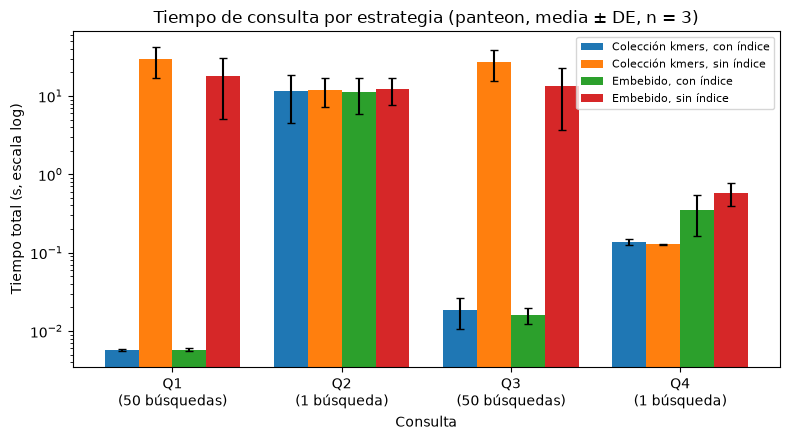

In [11]:
NOMBRES = {
    ("coleccion", "con_indice"): "Colección kmers, con índice",
    ("coleccion", "sin_indice"): "Colección kmers, sin índice",
    ("embebido", "con_indice"): "Embebido, con índice",
    ("embebido", "sin_indice"): "Embebido, sin índice",
}
consultas = sorted(medidas["consulta"].unique())
x = np.arange(len(consultas))
ancho = 0.2

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, ((a, v), nombre) in enumerate(NOMBRES.items()):
    sub = resumen.xs((a, v), level=["almacenamiento", "variante"]).reindex(consultas)
    ax.bar(x + (i - 1.5) * ancho, sub["t_total_media_s"], ancho, yerr=sub["t_total_de_s"].fillna(0),
           capsize=3, label=nombre)
ax.set_yscale("log")
ax.set_xticks(x, [f"{c}\n({N_BUSQUEDAS[c]} búsqueda{'s' if N_BUSQUEDAS[c] > 1 else ''})" for c in consultas])
ax.set_xlabel("Consulta")
ax.set_ylabel("Tiempo total (s, escala log)")
ax.set_title(f"Tiempo de consulta por estrategia ({DB_PRINCIPAL}, media ± DE, n = {REPETICIONES})")
ax.legend(fontsize=8)
fig.tight_layout()
Path(FIGURA).parent.mkdir(exist_ok=True)
fig.savefig(FIGURA, dpi=300)
plt.show()

## 8. Interpretación

### Q1: perfil de un k

Los índices reducen el tiempo de la mayoría de las consultas, aunque, como se verá en Q2 y Q4, hay consultas cuya estructura no les permite aprovecharlos.

En Q1 se recuperan los conteos de 2-mers (k = 2) de una secuencia, y la búsqueda se repite para 50 identificadores elegidos al azar con semilla fija, los mismos en ambas estrategias. Con índice, MongoDB va directamente al documento buscado (IXSCAN), revisando una sola clave y un solo documento por búsqueda, por lo que ambas estrategias obtienen tiempos prácticamente iguales: 0,114 ms por búsqueda en la colección `kmers` y 0,115 ms en `tes_embebidos` (media de 3 repeticiones).

Sin índice, MongoDB tiene que recorrer la colección completa en cada búsqueda: 1.439.676 documentos en la colección `kmers`, que tiene 6 documentos por TE, uno por cada k, y 239.946 en `tes_embebidos`, que tiene uno por TE. Esto eleva el tiempo a 596 ms por búsqueda en la colección y a 360 ms en la embebida. La embebida es más rápida en este caso porque recorre 6 veces menos documentos, aunque cada uno sea más grande.

En conclusión, con índice ambas estrategias son equivalentes para esta consulta, y el índice importa mucho más que la forma de almacenamiento: acelera la búsqueda unas 5.000 veces en la colección y unas 3.100 veces en la embebida.

### Q3: perfil completo

En Q3 se recuperan los 6 perfiles (k = 1 a 6) de una secuencia, repitiendo la búsqueda para los mismos 50 identificadores de Q1.

Con índice, la colección `kmers` va directamente a los 6 documentos de la secuencia (uno por k), revisando 6 documentos con un tiempo medio de 0,372 ms por búsqueda. En `tes_embebidos`, los 6 perfiles están en un solo documento, por lo que se revisa un único documento en 0,318 ms. La embebida es ligeramente más rápida, pero la diferencia es menor que la variación entre repeticiones (±0,16 y ±0,07 ms), así que, en la práctica, ambas estrategias son equivalentes.

Sin índice, la colección `kmers` debe recorrer sus 1.439.676 documentos en cada búsqueda, porque los 6 documentos de la secuencia pueden estar en cualquier parte, lo que lleva a 540 ms por búsqueda. En la embebida, la búsqueda se detiene en cuanto encuentra el documento: para la primera secuencia de la muestra revisó 174.247 de los 239.946 documentos, y en promedio tardó 267 ms por búsqueda. Sin índice, la embebida es unas 2 veces más rápida, porque tiene 6 veces menos documentos y puede detenerse antes.

En conclusión, igual que en Q1, con índice ambas estrategias son equivalentes, y el índice es lo que más influye en el tiempo: acelera la búsqueda unas 1.450 veces en la colección y unas 840 veces en la embebida. La ventaja de la embebida al traer los 6 perfiles en un solo documento solo se nota claramente sin índice, un escenario que no se usaría en la práctica.

### Q2: heatmap de 2-mers por orden

En Q2 se calcula, para cada orden de TE (LTR, LINE, TIR…), la frecuencia promedio de cada uno de los 16 pares de nucleótidos, a partir de los perfiles de k = 2 de los 239.946 TEs. A diferencia de Q1 y Q3, no es una búsqueda puntual sino un cálculo sobre toda la base.

Las cuatro combinaciones hacen el mismo cálculo y solo difieren en cómo leen los datos. La colección `kmers` con índice usa el índice `{k, te_order}` para leer únicamente los 239.946 documentos de k = 2; sin índice, recorre sus 1.439.676 documentos y descarta los demás valores de k. En `tes_embebidos`, el índice no sirve, porque los seis perfiles están en el mismo documento y no se pueden filtrar por k: con o sin índice, se leen los 239.946 documentos completos. Aun así, los tiempos totales fueron muy parecidos: 11,7 s y 12,0 s en la colección (con y sin índice) y 11,3 s y 12,4 s en la embebida, con una variación alta entre repeticiones (entre 3,5 y 16,7 s en una misma combinación).

El empate se explica porque, con los datos en memoria, el costo dominante no es la lectura sino el cálculo de la agregación: convertir los conteos en frecuencias, desenrollar los 16 valores de cada TE (unos 3,8 millones de elementos) y sumarlos por orden, un trabajo idéntico en ambas estrategias. La diferencia sí aparece en la etapa de lectura: según `explain`, la colección con índice leyó los datos en 4,0 s, frente a 15–17 s en las demás combinaciones. Esta cifra debe tomarse como un indicio, porque proviene de una sola ejecución realizada antes del calentamiento, cuando los datos aún no estaban en memoria.

En conclusión, con el volumen actual ninguna estrategia gana en esta consulta. Sin embargo, si el volumen creciera hasta no caber en memoria, la lectura pasaría a dominar, y es esperable que la colección aparte con índice, que según `explain` lee unas 4 veces más rápido, resulte más rápida. Esta hipótesis no se midió en este experimento.

### Q4: conteo sin k-mers

En esta consulta se buscó cuántos TEs hay de cada orden en cada reino, mediante una agregación con `$group`, el equivalente a `GROUP BY` por reino y orden. En la colección aparte se usa solo la colección `tes`, y en la embebida, `tes_embebidos`, que tiene los 6 perfiles de k-mers dentro de cada documento.

En los cuatro casos se examinaron los 239.946 documentos y ninguno usó índice, porque para contar todos los TEs hay que leerlos todos; por eso las diferencias entre “con” y “sin” índice son solo variación de la medición. Lo que sí cambió fue el tiempo según la estrategia: la colección aparte tardó 138 ms (con índice) y 128 ms (sin índice) en promedio, mientras que la embebida tardó 352 ms y 581 ms. Es decir, la embebida fue entre 2,5 y 4,5 veces más lenta. La razón es el peso de los k-mers: cada documento de `tes_embebidos` pesa unos 34.000 bytes, frente a unos 300 de `tes`, y aunque la consulta no usa los k-mers, MongoDB tiene que leer los documentos completos. Esto también se ve en el `explain`, donde la lectura en la embebida tardó entre 665 y 2.428 ms, frente a unos 170 ms en la colección.

### Qué estrategia conviene según el uso

Cuando se buscan los k-mers de una secuencia, como en Q1 y Q3, las dos estrategias tardan lo mismo si hay índice, así que lo importante es tener el índice. En el heatmap de Q2 también empatan con el volumen actual, aunque la colección aparte lee menos datos y podría ganar si la base creciera. Donde sí hay una diferencia importante es en las consultas que no usan k-mers, como Q4, debido a que ahí la embebida es entre 2,5 y 4,5 veces más lenta, porque carga con los k-mers aunque no los necesite.

Por eso se mantiene la colección aparte; además, la mayoría de las consultas del proyecto no usan k-mers, y con esta estrategia no pagan su peso. La embebida solo ofrece una carga un 5,5 % más rápida e índices más pequeños, lo que no compensa que todas las demás consultas sean más lentas.

### Limitaciones

Los resultados deben tomarse con algunas precauciones:

- Primero, en Q2 y en las variantes sin índice los tiempos variaron mucho entre repeticiones (por ejemplo, en Q2, entre 3,5 y 16,7 s en una misma combinación). Esto se debe al efecto de la caché, y es que las dos colecciones pesan unos 8 GB sin comprimir cada una, y al alternarlas una saca a la otra de la memoria, así que cada medición depende de si los datos ya estaban cargados.
- Segundo, solo se hicieron 3 repeticiones, lo que es poco para conclusiones firmes cuando la variación es tan alta.
- Tercero, todo se midió en una sola máquina Apple M5 con 24 GB de RAM, por lo que los tiempos podrían cambiar en otro equipo.
- Cuarto, los tiempos de lectura del `explain` vienen de una sola ejecución, hecha antes del calentamiento, así que solo sirven como indicio.
- Por último, con el volumen actual los datos caben en memoria; lo que pasaría con 10 o 100 veces más datos es una hipótesis que no se midió.